# AI Product Strategy and Business Skills

> **Who is this for?** You can build and deploy AI systems. Now you want the skills that decide **what** gets built, **whether** to build or buy it, **which** model or vendor to use, how to **price** it, how to help a company plan its AI work, how technical people take part in **sales and evaluations**, and how to **present** results and **write** technical documents that people act on.
>
> **What you will learn:**
> - **AI product management**: framing the problem (is AI even the right tool?), defining quality with a failure taxonomy, **eval-driven roadmaps**, human-in-the-loop UX and choosing an automation threshold, and **pricing models** (per seat, usage, outcome) with a margin simulation
> - **build vs buy vs partner**: a weighted decision matrix and a 3-year **total cost of ownership (TCO)** model
> - **vendor and model evaluation**: a scorecard over quality, cost, latency, security and terms, with hard gates and a cost-quality Pareto chart
> - **AI strategy and transformation**: centres of excellence, choosing a use-case portfolio under a budget, and governance with risk tiers
> - **pre-sales technical evaluations**: the technical win, RFI / RFP / RFQ, a requirements compliance matrix, POC success plans
> - **working with go-to-market teams**: roles, sales stages, and deal qualification frameworks (BANT, MEDDICC) explained neutrally
> - **competitive landscape analysis** done honestly
> - **presentations and demos**: structure, storytelling with data, and turning eval results into an **executive one-pager** with code
> - **writing technical docs**: design docs, RFCs, ADRs and reference architectures, with a small document checker
>
> **Prerequisites:** [01 AI roles](01_ai_roles_and_how_ai_work_gets_done.ipynb) and [02 forward deployed engineering in practice](02_forward_deployed_engineering_in_practice.ipynb). Helpful: [LLM evaluation hands-on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [tokens, cost and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb), [data visualisation and storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. numpy, pandas, matplotlib and the standard library. All companies, vendors, models and numbers are made up; prices are illustrative only.

## Explained simply

Running an AI product is like **running a restaurant**. The chef can cook (the engineers can build), but someone must decide the menu (product management), whether to make the bread in-house or buy it from a bakery (build vs buy), which suppliers to trust (vendor evaluation), what to charge (pricing), how the restaurant group opens new branches (strategy), how to win a big catering contract (pre-sales), and how to explain to the owners why profits went up or down (presentations and writing).

**Tiny example.** A company wants an AI assistant that answers employees' HR questions. A good product thinker asks first: *how many questions, how many are the same ten questions, what goes wrong when the answer is wrong?* If 70% are the same ten questions, a well-written FAQ page solves most of it; the AI handles the long tail and hands sensitive cases (pay disputes, health) to a person. Then: build on a model API, or buy an HR assistant product? The answer depends on how special the company's needs are, the 3-year cost, and the security terms, and all of these can be written down and scored.

| Skill | The question it answers | Section |
|---|---|---|
| Problem framing | Is this a problem worth solving, and does it need AI? | 1.1 |
| Defining quality | What does "good" mean, and how do we measure it? | 1.2-1.3 |
| Human-in-the-loop UX | When should a person check the AI? | 1.4 |
| Pricing | How do we charge so value and costs line up? | 1.5 |
| Build vs buy | Make it, buy it, or partner? | 2 |
| Vendor / model evaluation | Which option is best for *our* needs? | 3 |
| Strategy | Which use cases, in what order, with what rules? | 4 |
| Pre-sales and GTM | How does a customer evaluate and buy? | 5-7 |
| Communication | How do we present and write so people decide? | 8-9 |

### Table of contents
0. Setup
1. AI product management
2. Build vs buy vs partner
3. Vendor and model evaluation
4. AI strategy and transformation
5. Pre-sales technical evaluations
6. Working with go-to-market teams
7. Competitive landscape analysis
8. Presentations, demos and the executive one-pager
9. Writing technical documents
10. Recap, interview questions and further reading

---
## 0. Setup

In [1]:
import math, re, textwrap
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEED = 11
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 30)
print("ready")

ready


---
## 1. AI product management

**What it is.** **Product management** decides what to build, for whom, why, and how to know it worked. **AI product management** adds three things that ordinary software does not have to the same degree: the output is **probabilistic** (sometimes wrong), **quality must be defined and measured** explicitly (evals), and the **cost per use** can be significant (tokens, GPUs).

**Simple analogy.** A normal product is a vending machine: press B4, get B4. An AI product is a new employee: usually helpful, sometimes wrong, and you need training, checking and clear rules about what they may do alone.

### 1.1 Problem framing: is AI the right tool?

**How it works.** Write the problem as *who* has *what* problem, *how often*, and *what it costs today*. Then ask whether the task really needs AI:

| If the task... | Usually best tool |
|---|---|
| has clear, stable rules and few cases | Plain code, rules, a form or a lookup table |
| is a prediction from structured data with labelled history (churn, fraud, demand) | Classic ML ([03_Machine_Learning](../03_Machine_Learning/)) |
| involves understanding or writing language, documents or images, with many variations | An LLM (with retrieval if it needs company knowledge) |
| needs several steps with tools, where the steps are not known in advance | An agent, with limits and checks ([10_Agents](../10_Agents/)) |
| needs a guaranteed correct answer every time, and mistakes are very costly | Not AI alone: AI can suggest, a person or a rule decides |

**When to use it.** Before any design work. Many AI projects fail because a simpler tool would have been better, or because the problem was not worth solving.

In [2]:
def recommend_approach(task: dict) -> str:
    # A simple decision helper mirroring the table above. Real decisions need judgement; this makes the reasoning explicit.
    if task["rules_are_clear"] and task["variety"] == "low":
        return "plain code / rules (cheaper, testable, predictable)"
    if task["input"] == "structured" and task["labelled_history"]:
        return "classic ML model"
    if task["mistake_cost"] == "very high" and not task["human_can_review"]:
        return "do not automate: AI may suggest, a person or rule decides"
    if task["multi_step_with_tools"]:
        return "agent with tool limits, approvals and evals" + (" + human review" if task["human_can_review"] else "")
    return "LLM (+ retrieval if company knowledge is needed)" + (" with human review" if task["human_can_review"] else "")

examples = {
    "Route invoices by supplier code":      dict(rules_are_clear=True,  variety="low",  input="structured", labelled_history=False, mistake_cost="low", human_can_review=False, multi_step_with_tools=False),
    "Predict which customers will cancel":  dict(rules_are_clear=False, variety="high", input="structured", labelled_history=True,  mistake_cost="low", human_can_review=False, multi_step_with_tools=False),
    "Answer employees' HR policy questions":dict(rules_are_clear=False, variety="high", input="text",       labelled_history=False, mistake_cost="medium", human_can_review=True, multi_step_with_tools=False),
    "Approve insurance claims alone":       dict(rules_are_clear=False, variety="high", input="text",       labelled_history=True,  mistake_cost="very high", human_can_review=False, multi_step_with_tools=True),
    "Research a supplier and draft a memo": dict(rules_are_clear=False, variety="high", input="text",       labelled_history=False, mistake_cost="medium", human_can_review=True, multi_step_with_tools=True),
}
for name, t in examples.items():
    print(f"{name:40s} -> {recommend_approach(t)}")

Route invoices by supplier code          -> plain code / rules (cheaper, testable, predictable)
Predict which customers will cancel      -> classic ML model
Answer employees' HR policy questions    -> LLM (+ retrieval if company knowledge is needed) with human review
Approve insurance claims alone           -> do not automate: AI may suggest, a person or rule decides
Research a supplier and draft a memo     -> agent with tool limits, approvals and evals + human review


**Note.** "Approve insurance claims alone" is a text task with labelled history, but the order of the rules matters: because the mistake cost is very high and no person reviews, the helper refuses full automation. The structured-data rule fires first only when the input is structured.

### 1.2 Defining quality: a failure taxonomy from error analysis

**What it is.** "Quality" for an AI feature is a list of specific, checkable properties: correct, grounded in sources, complete, safe, in the right tone, in the right format, fast enough. The most reliable way to find what matters is **error analysis**: read a sample of real outputs, write down what went wrong in plain words, then group the notes into a **failure taxonomy** (a list of failure types) and count them.

**Simple analogy.** A teacher marking 50 essays notices that most lost points for the same three reasons. Those three reasons become the focus of the next lessons.

**How it works.** (1) Sample 50-100 real outputs. (2) For each failure, write a short note. (3) Group notes into failure modes. (4) Count frequency and rate severity. (5) Turn the top modes into eval checks (code checks where possible, judged checks otherwise). This approach is described well by practitioners such as Hamel Husain and Shreya Shankar (see Further reading).

In [3]:
# 80 reviewed outputs from an HR assistant pilot (made up). Each failure note was grouped into one failure mode.
failure_log = pd.DataFrame({
    "mode": (["answer from outdated policy"] * 11 + ["no source cited"] * 9 + ["missed escalation (sensitive topic)"] * 4 +
             ["too long / hard to read"] * 8 + ["wrong country's policy"] * 6 + ["refused a normal question"] * 3),
})
SEVERITY = {"answer from outdated policy": 3, "no source cited": 2, "missed escalation (sensitive topic)": 3,
            "too long / hard to read": 1, "wrong country's policy": 3, "refused a normal question": 2}
N_REVIEWED = 80

tax = failure_log["mode"].value_counts().rename("count").to_frame()
tax["share_of_outputs"] = (tax["count"] / N_REVIEWED).round(3)
tax["severity"] = tax.index.map(SEVERITY)
tax["priority"] = tax["count"] * tax["severity"]
tax = tax.sort_values("priority", ascending=False)
print(f"reviewed {N_REVIEWED} outputs, {len(failure_log)} had a failure ({len(failure_log)/N_REVIEWED:.0%})")
print(tax.to_string())

reviewed 80 outputs, 41 had a failure (51%)
                                     count  share_of_outputs  severity  priority
mode                                                                            
answer from outdated policy             11             0.138         3        33
no source cited                          9             0.112         2        18
wrong country's policy                   6             0.075         3        18
missed escalation (sensitive topic)      4             0.050         3        12
too long / hard to read                  8             0.100         1         8
refused a normal question                3             0.038         2         6


### 1.3 Eval-driven roadmaps

**What it is.** An **eval-driven roadmap** ties every planned improvement to a failure mode and to an eval that will show whether it worked. Instead of "improve the assistant", a roadmap item reads "*fix outdated-policy answers: add effective-date filter; target: outdated-answer rate below 2% on the 'policy versions' eval slice*".

**How it works.** For each top failure mode: propose a fix, estimate effort, estimate the expected reduction, and define the eval slice and target. Rank by expected gain per unit of effort. After shipping, the eval tells you whether to close the item.

In [4]:
roadmap = pd.DataFrame([
    # failure mode,                         fix,                                          effort (weeks), expected share of mode removed
    ("answer from outdated policy",         "effective-date metadata + retrieval filter",     2, 0.85),
    ("wrong country's policy",              "ask/derive employee country; filter by country", 1, 0.90),
    ("missed escalation (sensitive topic)", "sensitive-topic classifier + always escalate",   2, 0.75),
    ("no source cited",                     "require citations in structured output",         1, 0.80),
    ("too long / hard to read",             "length limit + format instructions",             0.5, 0.60),
    ("refused a normal question",           "adjust refusal guidance; add 20 eval cases",     0.5, 0.60),
], columns=["mode", "fix", "effort_weeks", "expected_removal"])

roadmap = roadmap.merge(tax[["count", "severity"]], left_on="mode", right_index=True)
roadmap["expected_gain"] = roadmap["count"] * roadmap["severity"] * roadmap["expected_removal"]
roadmap["gain_per_week"] = (roadmap["expected_gain"] / roadmap["effort_weeks"]).round(1)
roadmap["eval_target"] = roadmap["mode"].map(lambda m: f"'{m}' rate < 2% on its eval slice")
roadmap = roadmap.sort_values("gain_per_week", ascending=False).reset_index(drop=True)
roadmap.index += 1
print(roadmap[["mode", "fix", "effort_weeks", "gain_per_week", "eval_target"]].to_string())

                                  mode                                             fix  effort_weeks  gain_per_week                                                        eval_target
1               wrong country's policy  ask/derive employee country; filter by country           1.0           16.2               'wrong country's policy' rate < 2% on its eval slice
2                      no source cited          require citations in structured output           1.0           14.4                      'no source cited' rate < 2% on its eval slice
3          answer from outdated policy      effective-date metadata + retrieval filter           2.0           14.0          'answer from outdated policy' rate < 2% on its eval slice
4              too long / hard to read              length limit + format instructions           0.5            9.6              'too long / hard to read' rate < 2% on its eval slice
5            refused a normal question      adjust refusal guidance; add 20 eval case

**What just happened?** The ranking puts cheap, high-severity fixes first (country filter, citations) and the more expensive classifier later, but still early because missed escalations are severe. Every item has a measurable target, so the roadmap review becomes "did the eval move?" rather than opinions. Eval methods themselves are in [LLM evaluation hands-on](../08_LLM/22_llm_evaluation_hands_on.ipynb).

### 1.4 Human-in-the-loop UX and choosing an automation threshold

**What it is.** **Human-in-the-loop (HITL)** design decides where people check, correct or approve AI output. Common patterns:

| Pattern | What the user sees | Use when |
|---|---|---|
| **Suggest** | AI drafts, person edits and sends | Early phases, customer-facing text |
| **Approve** | AI proposes an action, person clicks approve | Actions with moderate risk (refund under a limit) |
| **Auto with review sample** | AI acts alone; a sample is reviewed later | High volume, low risk, well-measured quality |
| **Auto with confidence gate** | AI acts alone only when confident, otherwise hands to a person | Mixed risk; needs calibrated confidence |
| **Escalate** | AI routes to the right person with a summary | Sensitive or out-of-scope cases |

Good HITL UX also shows **sources** (citations), makes **undo** easy, explains **why** something was escalated, and makes giving **feedback** one click.

**Choosing a threshold.** With a confidence gate, a higher threshold means fewer automated cases but fewer errors. Pick the threshold that automates as much as possible **while staying inside an agreed error budget** (for example "at most 1% of automated answers wrong"). This needs confidence scores that are **calibrated** (see [model calibration](../03_Machine_Learning/01_supervised/13_model_calibration.ipynb) and [prediction sets with human review](../03_Machine_Learning/14_conformal_prediction/02_industry_prediction_sets_with_human_review.ipynb)).

 threshold  automation_rate  error_rate_when_auto
      0.50            0.888                 0.139
      0.58            0.792                 0.121
      0.66            0.659                 0.095
      0.74            0.480                 0.070
      0.82            0.292                 0.034
      0.90            0.114                 0.007
      0.98            0.004                 0.000

lowest threshold within a 5% error budget: 0.80 -> automates 34% of cases


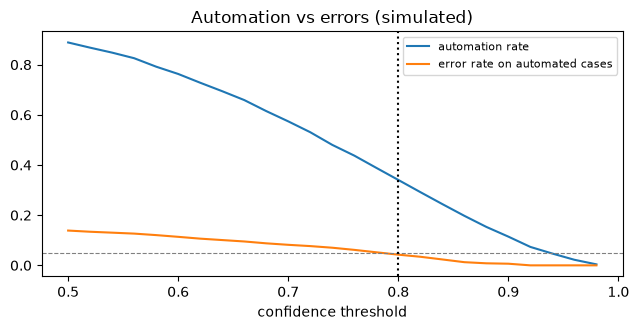

In [5]:
# Simulated validation set: confidence scores and whether the AI was correct (higher confidence -> more often correct).
n = 4000
conf = rng.beta(5, 2, n)
correct = rng.random(n) < np.minimum(1.0, 0.30 + 0.75 * conf)

rows = []
for thr in np.arange(0.50, 0.99, 0.02):
    auto = conf >= thr
    rows.append({"threshold": round(thr, 2), "automation_rate": auto.mean(), "error_rate_when_auto": 1 - correct[auto].mean()})
curve = pd.DataFrame(rows)
ERROR_BUDGET = 0.05
ok = curve[curve["error_rate_when_auto"] <= ERROR_BUDGET]
best = ok.iloc[0] if len(ok) else None
print(curve.iloc[::4].round(3).to_string(index=False))
if best is not None:
    print(f"\nlowest threshold within a {ERROR_BUDGET:.0%} error budget: {best['threshold']:.2f} -> automates {best['automation_rate']:.0%} of cases")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(curve["threshold"], curve["automation_rate"], label="automation rate")
ax.plot(curve["threshold"], curve["error_rate_when_auto"], label="error rate on automated cases")
ax.axhline(ERROR_BUDGET, ls="--", color="grey", lw=0.8)
if best is not None: ax.axvline(best["threshold"], ls=":", color="k")
ax.set_xlabel("confidence threshold"); ax.legend(fontsize=8); ax.set_title("Automation vs errors (simulated)")
plt.tight_layout(); plt.show()

### 1.5 Pricing models for AI products

**What they are.**

| Model | How the customer pays | Good for | Risk |
|---|---|---|---|
| **Per seat** (subscription per user) | Fixed price per user per month | Tools used by people daily (assistants, copilots) | Heavy users can cost more in model usage than they pay |
| **Usage-based** | Per request, per token, per document, per minute | APIs, variable workloads | Bills are hard for customers to predict |
| **Outcome-based** | Per resolved ticket, per successful task, per qualified lead | Products that complete work end to end (for example support agents) | Needs a clear, agreed definition of "outcome" and reliable measurement |
| **Hybrid** | Platform fee + usage or outcome tiers, often with credits | Most enterprise AI products | More complex to explain |

**Simple analogy.** A gym membership (per seat), a taxi meter (usage), a lawyer paid only if you win (outcome), or a phone plan with a monthly fee plus extra data (hybrid).

**Why AI makes pricing harder.** Each use has a **real variable cost** (model tokens, GPU time). With per-seat pricing, a customer whose users run long, heavy tasks can make the product *lose money*. Pricing should keep **gross margin** (revenue minus direct costs, as a share of revenue) healthy across the realistic range of usage. The simulation below compares the three models for three kinds of customers.

In [6]:
COST_PER_TASK = 0.06            # illustrative model + infra cost per completed task (USD)
PRICE = {"per_seat_month": 30.0, "per_task": 0.20, "per_outcome": 0.90}
OUTCOME_RATE = 0.65             # share of tasks that count as a successful outcome (e.g. resolved without a human)

customers = pd.DataFrame({
    "profile": ["light users", "typical", "heavy users"],
    "seats": [200, 200, 200],
    "tasks_per_seat_month": [40, 180, 900],
})

def margins(c: pd.DataFrame) -> pd.DataFrame:
    c = c.copy()
    tasks = c["seats"] * c["tasks_per_seat_month"]
    cost = tasks * COST_PER_TASK
    revenue = {"per seat": c["seats"] * PRICE["per_seat_month"], "usage": tasks * PRICE["per_task"],
               "outcome": tasks * OUTCOME_RATE * PRICE["per_outcome"]}
    for model, rev in revenue.items():
        c[f"margin_{model}"] = ((rev - cost) / rev).round(2)
        c[f"revenue_{model}"] = rev.round(0)
    return c

m = margins(customers)
print(m[["profile", "tasks_per_seat_month", "revenue_per seat", "margin_per seat", "revenue_usage", "margin_usage", "revenue_outcome", "margin_outcome"]].to_string(index=False))

    profile  tasks_per_seat_month  revenue_per seat  margin_per seat  revenue_usage  margin_usage  revenue_outcome  margin_outcome
light users                    40            6000.0             0.92         1600.0           0.7           4680.0             0.9
    typical                   180            6000.0             0.64         7200.0           0.7          21060.0             0.9
heavy users                   900            6000.0            -0.80        36000.0           0.7         105300.0             0.9


**What just happened?** Per-seat pricing gives a high margin on light users but a **negative margin** on heavy users. Usage and outcome pricing keep the margin stable, because revenue grows with cost; outcome pricing also matches what the customer values (work done), but only works if "outcome" is clearly defined and measured. This is why many AI products use **hybrid** pricing (a seat or platform fee plus usage or outcome tiers), and why product teams track **cost per task** as closely as quality. Ways to lower cost per task are in [tokens, cost and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb).

---
## 2. Build vs buy vs partner

**What it is.** For any capability, an organisation can **build** it (its own engineers, usually on top of model APIs or open models), **buy** it (a finished product or SaaS), or **partner** (a vendor or systems integrator builds and runs it together with you). The choice is rarely all-or-nothing: many teams buy the platform and build the parts that make them different.

**Simple analogy.** Getting a kitchen: build it yourself from parts, buy a ready-made kitchen, or hire a kitchen company that designs and fits it with you.

**How it works.**
1. **Clarify the need**: is this capability a **differentiator** (part of how you compete) or **commodity** (everyone needs it, nobody wins with it)? Build differentiators; buy commodities.
2. **Score options on agreed criteria** with weights (decision matrix).
3. **Compare total cost of ownership (TCO)** over 3 years: not just licence vs salaries, but also build time, maintenance, model usage, infrastructure, security reviews, training and switching costs.
4. **Check the risks**: vendor lock-in, vendor viability, data terms, your team's ability to maintain what it builds.
5. **Decide, and write down what would change the decision** (for example "if usage passes 2 million tasks per month, revisit building").

In [7]:
criteria = pd.DataFrame([
    # criterion,                     weight, build, buy, partner   (scores 1-5, higher is better)
    ("Fit to our specific workflow",   0.25,   5,    3,    4),
    ("Time to value",                  0.20,   2,    5,    4),
    ("3-year cost (see TCO below)",    0.15,   2,    4,    4),
    ("Control over data and models",   0.15,   5,    2,    4),
    ("Team can maintain it",           0.10,   2,    5,    4),
    ("Vendor / lock-in risk (5 = low)",0.10,   5,    2,    3),
    ("Security and compliance effort", 0.05,   2,    4,    3),
], columns=["criterion", "weight", "build", "buy", "partner"])
assert abs(criteria["weight"].sum() - 1) < 1e-9, "weights must add up to 1"

weighted = (criteria[["build", "buy", "partner"]].mul(criteria["weight"], axis=0)).sum().round(2)
print(criteria.to_string(index=False)); print("\nweighted scores:", weighted.to_dict())

                      criterion  weight  build  buy  partner
   Fit to our specific workflow    0.25      5    3        4
                  Time to value    0.20      2    5        4
    3-year cost (see TCO below)    0.15      2    4        4
   Control over data and models    0.15      5    2        4
           Team can maintain it    0.10      2    5        4
Vendor / lock-in risk (5 = low)    0.10      5    2        3
 Security and compliance effort    0.05      2    4        3

weighted scores: {'build': 3.5, 'buy': 3.55, 'partner': 3.85}


In [8]:
def tco(option: str, years: int = 3, tasks_per_month: float = 300_000) -> pd.Series:
    # Illustrative 3-year total cost of ownership. All figures are made-up assumptions for teaching.
    months = 12 * years
    if option == "build":
        one_time = 4 * 4 * 16_000            # 4 engineers x 4 months x monthly cost
        monthly = 1.25 * 16_000 + tasks_per_month * 0.008 + 2_000  # 1.25 engineers to maintain + model usage + infra
    elif option == "buy":
        one_time = 25_000                    # setup, integration, security review
        monthly = 15_000 + tasks_per_month * 0.03   # licence + usage-based fees (vendor margin included)
    else:  # partner
        one_time = 120_000                   # partner build project
        monthly = 9_000 + tasks_per_month * 0.012 + 0.5 * 16_000
    return pd.Series({"one_time": one_time, "monthly_run": monthly, f"tco_{years}y": one_time + monthly * months})

tco_table = pd.DataFrame({o: tco(o) for o in ["build", "buy", "partner"]}).T.round(0)
print(tco_table.to_string())

# How does the cheapest option change with volume?
vols = [50_000, 300_000, 1_000_000, 3_000_000, 5_000_000]
print("\ncheapest option by monthly volume:")
for v in vols:
    costs = {o: tco(o, tasks_per_month=v)["tco_3y"] for o in ["build", "buy", "partner"]}
    print(f"  {v:>9,} tasks/month -> {min(costs, key=costs.get):7s} ({ {k: round(c/1e3) for k, c in costs.items()} } thousand)")

         one_time  monthly_run     tco_3y
build    256000.0      24400.0  1134400.0
buy       25000.0      24000.0   889000.0
partner  120000.0      20600.0   861600.0

cheapest option by monthly volume:
     50,000 tasks/month -> buy     ({'build': 1062, 'buy': 619, 'partner': 754} thousand)
    300,000 tasks/month -> partner ({'build': 1134, 'buy': 889, 'partner': 862} thousand)
  1,000,000 tasks/month -> partner ({'build': 1336, 'buy': 1645, 'partner': 1164} thousand)
  3,000,000 tasks/month -> build   ({'build': 1912, 'buy': 3805, 'partner': 2028} thousand)
  5,000,000 tasks/month -> build   ({'build': 2488, 'buy': 5965, 'partner': 2892} thousand)


**What just happened?** The weighted matrix favours **partner**: nearly as good a fit as building, much faster, and cheaper over three years. The TCO model shows how the answer moves with volume: **buy** is cheapest at low volume, **partner** in the middle (today's 300,000 tasks per month), and **build** only at very high volume, where the vendor's per-task fees dominate. This is the typical pattern: buying wins on speed and at low volume; building wins on control and at high volume or high differentiation. Writing it down produces a **decision with a trigger**: "partner now; revisit building if volume passes about 3 million tasks per month or the workflow becomes a key differentiator". Cloud cost modelling in more depth: [cloud architecture and cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb).

---
## 3. Vendor and model evaluation

**What it is.** A structured comparison of vendors or models on **your** tasks and **your** requirements: quality (on your eval set), cost, latency, security and compliance, and contract terms (data use, retention, residency, support, price stability).

**Simple analogy.** Choosing a car for a delivery business: you test-drive on your own routes, check fuel cost and reliability, and read the warranty, rather than trusting the advert.

**How it works.**
1. **Hard gates first**: requirements that remove an option entirely (for example "data must stay in the EU", "SOC 2 Type II", "no training on our data"). Failing one gate means out, whatever the score.
2. **Measure on your own eval set**: quality, p95 latency, cost per task. Public benchmarks are a starting point only.
3. **Normalise and weight**: turn each metric into a 0-1 score (best = 1), apply weights agreed beforehand.
4. **Look at the trade-off**, not only the winner: the **Pareto frontier** shows options that are not beaten on both quality and cost at once.
5. **Re-run regularly**: models and prices change often (as of late 2026, new versions arrive every few months), so keep the evaluation as code.

In [9]:
# Results of running the SAME 400-task eval set on five candidate options (made-up names and numbers).
candidates = pd.DataFrame([
    # option,                  quality, p95_latency_s, cost_per_1k_tasks, eu_residency, soc2_type2, no_training_on_data, terms (1-5)
    ("Model A (large)",          0.91,      6.5,           42.0,            True,  True,  True,  4),
    ("Model B (medium)",         0.88,      2.8,           12.0,            True,  True,  True,  4),
    ("Model C (small)",          0.81,      1.1,            2.5,            True,  True,  True,  3),
    ("Vendor D (product)",       0.86,      3.5,           30.0,            False, True,  True,  3),
    ("Open model E (self-host)", 0.84,      2.2,            6.0,            True,  None,  True,  5),   # self-hosted: our own controls apply
], columns=["option", "quality", "p95_latency_s", "cost_per_1k", "eu_residency", "soc2_type2", "no_training_on_data", "terms"])

def gates(row) -> str:
    fails = [g for g in ["eu_residency", "soc2_type2", "no_training_on_data"] if row[g] is False]
    return "pass" if not fails else "FAIL: " + ", ".join(fails)
candidates["gates"] = candidates.apply(gates, axis=1)

W = {"quality": 0.45, "cost": 0.25, "latency": 0.15, "terms": 0.15}
ok = candidates[candidates["gates"] == "pass"].copy()
ok["s_quality"] = (ok["quality"] - ok["quality"].min()) / (ok["quality"].max() - ok["quality"].min())
ok["s_cost"] = (ok["cost_per_1k"].max() - ok["cost_per_1k"]) / (ok["cost_per_1k"].max() - ok["cost_per_1k"].min())
ok["s_latency"] = (ok["p95_latency_s"].max() - ok["p95_latency_s"]) / (ok["p95_latency_s"].max() - ok["p95_latency_s"].min())
ok["s_terms"] = (ok["terms"] - 1) / 4
ok["score"] = (W["quality"] * ok["s_quality"] + W["cost"] * ok["s_cost"] + W["latency"] * ok["s_latency"] + W["terms"] * ok["s_terms"]).round(3)
print(candidates[["option", "gates"]].to_string(index=False))
print()
print(ok.sort_values("score", ascending=False)[["option", "quality", "p95_latency_s", "cost_per_1k", "terms", "score"]].to_string(index=False))

                  option              gates
         Model A (large)               pass
        Model B (medium)               pass
         Model C (small)               pass
      Vendor D (product) FAIL: eu_residency
Open model E (self-host)               pass

                  option  quality  p95_latency_s  cost_per_1k  terms  score
        Model B (medium)     0.88            2.8         12.0      4  0.720
Open model E (self-host)     0.84            2.2          6.0      5  0.632
         Model A (large)     0.91            6.5         42.0      4  0.562
         Model C (small)     0.81            1.1          2.5      3  0.475


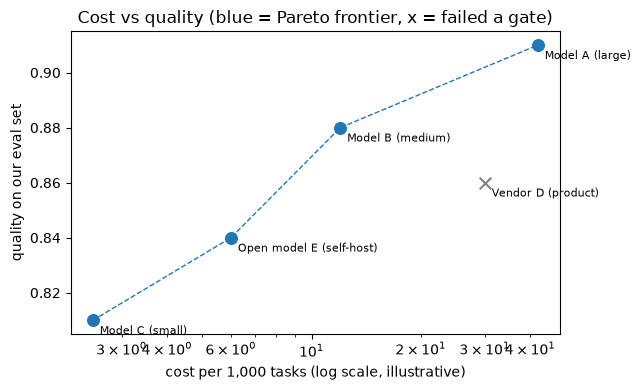

In [10]:
def pareto(df):
    # An option is on the frontier if no other option is at least as good on quality AND at least as cheap, and better on one.
    front = []
    for i, r in df.iterrows():
        dominated = ((df["quality"] >= r["quality"]) & (df["cost_per_1k"] <= r["cost_per_1k"]) &
                     ((df["quality"] > r["quality"]) | (df["cost_per_1k"] < r["cost_per_1k"]))).any()
        front.append(not dominated)
    return front

candidates["pareto"] = pareto(candidates)
fig, ax = plt.subplots(figsize=(6.5, 4))
for _, r in candidates.iterrows():
    ax.scatter(r["cost_per_1k"], r["quality"], s=70, marker="o" if r["gates"] == "pass" else "x",
               color="tab:blue" if r["pareto"] else "tab:grey")
    ax.annotate(r["option"], (r["cost_per_1k"], r["quality"]), xytext=(5, -10), textcoords="offset points", fontsize=8)
f = candidates[candidates["pareto"]].sort_values("cost_per_1k")
ax.plot(f["cost_per_1k"], f["quality"], "--", color="tab:blue", lw=1)
ax.set_xscale("log"); ax.set_xlabel("cost per 1,000 tasks (log scale, illustrative)"); ax.set_ylabel("quality on our eval set")
ax.set_title("Cost vs quality (blue = Pareto frontier, x = failed a gate)"); plt.tight_layout(); plt.show()

**What just happened?** Vendor D fails the EU-residency gate, so it is out whatever its score. Among the rest, the medium model B scores highest with these weights, but the Pareto chart shows the real choice: a small cheap model, a medium one, or the large one for about 3.5 times B's cost and 3 more quality points. A common design is **routing**: send easy tasks to the small model and hard ones to the large model (see [AI system design](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) and [how LLMs differ](../08_LLM/24_how_llms_differ_from_each_other.ipynb)). The weights are a business choice: agree them **before** seeing results, as in [model comparison and selection](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb).

---
## 4. AI strategy and transformation

**What it is.** An **AI strategy** says which business outcomes AI should help with, which use cases to pursue in what order, what platform and skills are needed, and what rules apply. **Transformation** is the multi-year work of changing processes, skills and culture so that AI is used widely and safely, not only in a few pilots.

**Simple analogy.** A city's transport plan: which lines to build first, which shared depots and signals they all need, and the safety rules every driver follows.

### 4.1 Operating models: the AI centre of excellence

An **AI centre of excellence (CoE)** is a team that sets standards, shares platforms and know-how, and helps business units deliver AI. Three common shapes:

| Model | How it works | Strength | Weakness |
|---|---|---|---|
| **Centralised** | One central team builds and runs most AI | Consistent quality, rare skills in one place | Becomes a bottleneck; far from the business |
| **Hub-and-spoke** | A central hub owns platform, standards and governance; "spokes" in business units build use cases | Balance of speed and consistency | Needs clear split of responsibilities |
| **Federated** | Business units build independently, with light shared standards | Fast, close to the problem | Duplication, uneven quality and risk control |

Many organisations start centralised and move towards hub-and-spoke as skills spread. A common description of the hub's job is to set the **responsible-AI requirements and common boundaries** inside which business teams are free to innovate.

A useful rule from cloud adoption guidance: prefer the option that meets the requirements **with the least operational responsibility** (a SaaS product before a low-code builder, a managed platform before running your own infrastructure), and move down the stack only when there is a clear reason.

### 4.2 A portfolio and a roadmap

**How it works.** Collect use cases from across the business (often with a discovery process like [notebook 02, section 2](02_forward_deployed_engineering_in_practice.ipynb)), estimate value, cost and risk, and choose a **portfolio**: a mix of quick wins (build trust), core improvements (most of the value) and a few bigger bets. Keep the choice under the budget and the team's capacity.

In [11]:
portfolio = pd.DataFrame([
    # use case,                              horizon,      value (k/yr), cost (k), risk 1-5, shared platform needed
    ("Support draft replies",                "quick win",      450,        150,      2, "retrieval"),
    ("Internal HR / IT assistant",           "quick win",      300,        120,      2, "retrieval"),
    ("Contract clause extraction",           "core",           700,        300,      3, "document parsing"),
    ("Sales call summaries to CRM",          "quick win",      200,         60,      1, "speech-to-text"),
    ("Demand forecasting upgrade",           "core",           900,        400,      2, "ml platform"),
    ("Claims triage agent",                  "core",          1200,        600,      4, "agents + evals"),
    ("Autonomous procurement negotiation",   "big bet",       1500,        900,      5, "agents + evals"),
    ("Marketing content generation",         "quick win",      150,         50,      2, "brand guardrails"),
], columns=["use_case", "horizon", "value_k", "cost_k", "risk", "platform"])

BUDGET_K = 1500
MAX_AVG_RISK = 3.0
portfolio["value_per_cost"] = (portfolio["value_k"] / portfolio["cost_k"]).round(2)

chosen, spent = [], 0
for _, r in portfolio.sort_values("value_per_cost", ascending=False).iterrows():
    trial = chosen + [r]
    if spent + r["cost_k"] <= BUDGET_K and np.mean([t["risk"] for t in trial]) <= MAX_AVG_RISK:
        chosen.append(r); spent += r["cost_k"]
plan = pd.DataFrame(chosen)
print(plan[["use_case", "horizon", "value_k", "cost_k", "risk", "value_per_cost"]].to_string(index=False))
print(f"\nspent {spent}k of {BUDGET_K}k | expected value {plan['value_k'].sum()}k/yr | average risk {plan['risk'].mean():.1f}")
print("horizon mix:", plan["horizon"].value_counts().to_dict())
print("shared platforms needed:", sorted(set(plan["platform"])))

                    use_case   horizon  value_k  cost_k  risk  value_per_cost
 Sales call summaries to CRM quick win      200      60     1            3.33
       Support draft replies quick win      450     150     2            3.00
Marketing content generation quick win      150      50     2            3.00
  Internal HR / IT assistant quick win      300     120     2            2.50
  Contract clause extraction      core      700     300     3            2.33
  Demand forecasting upgrade      core      900     400     2            2.25

spent 1080k of 1500k | expected value 2700k/yr | average risk 2.0
horizon mix: {'quick win': 4, 'core': 2}
shared platforms needed: ['brand guardrails', 'document parsing', 'ml platform', 'retrieval', 'speech-to-text']


**What just happened?** A simple greedy rule (best value per cost first, within budget and an average-risk limit) gives a portfolio of quick wins plus core projects. The "big bet" does not fit this year. The claims triage agent (high value, but risk 4 and a large cost) does not fit the remaining budget either. The **shared platforms** list is the strategic insight: two of the chosen use cases need retrieval, so building it once (with evals and access control) is a platform investment, which is exactly the hub's job in a hub-and-spoke model. Real portfolio decisions also weigh strategic fit and dependencies; the code just makes the trade-off visible.

### 4.3 Governance: rules that scale

**What it is.** **AI governance** is the set of policies, roles and processes that make AI use safe, legal and consistent: an acceptable-use policy, a **model and use-case inventory**, **risk tiers** with matching controls, review boards for high-risk uses, incident handling, and monitoring. Regulation such as the EU AI Act also uses risk categories (see [AI regulation and compliance](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb) and [accountability and governance](../00_AI_Fundamentals/03_accountability_and_governance.ipynb)). Management-system standards such as ISO/IEC 42001 describe how to run this as an organisation.

**How it works.** Classify each use case into a tier by its impact on people, its autonomy and the sensitivity of the data; each tier comes with required controls. Low-risk uses move fast; high-risk uses get more review.

In [12]:
def risk_tier(uc: dict) -> tuple:
    points = {"low": 0, "medium": 1, "high": 2}
    score = points[uc["impact_on_people"]] * 2 + points[uc["autonomy"]] + points[uc["data_sensitivity"]]
    if uc.get("prohibited_practice"):
        return "Not allowed", ["stop: practice not permitted by policy or law"]
    if score >= 6:
        return "Tier 3 (high)", ["review board approval", "documented evals incl. fairness", "human oversight", "incident plan", "audit log", "regular re-review"]
    if score >= 3:
        return "Tier 2 (medium)", ["owner sign-off", "eval report", "human review of a sample", "monitoring"]
    return "Tier 1 (low)", ["register in inventory", "follow acceptable-use policy"]

inventory = {
    "Marketing content generation": dict(impact_on_people="low", autonomy="low", data_sensitivity="low"),
    "Support draft replies":        dict(impact_on_people="medium", autonomy="low", data_sensitivity="medium"),
    "Claims triage agent":          dict(impact_on_people="high", autonomy="medium", data_sensitivity="high"),
    "CV screening that auto-rejects": dict(impact_on_people="high", autonomy="high", data_sensitivity="high"),
}
for name, uc in inventory.items():
    tier, controls = risk_tier(uc)
    print(f"{name:32s} {tier:16s} controls: {', '.join(controls)}")

Marketing content generation     Tier 1 (low)     controls: register in inventory, follow acceptable-use policy
Support draft replies            Tier 2 (medium)  controls: owner sign-off, eval report, human review of a sample, monitoring
Claims triage agent              Tier 3 (high)    controls: review board approval, documented evals incl. fairness, human oversight, incident plan, audit log, regular re-review
CV screening that auto-rejects   Tier 3 (high)    controls: review board approval, documented evals incl. fairness, human oversight, incident plan, audit log, regular re-review


---
## 5. Pre-sales technical evaluations

**What it is.** Before an enterprise buys, it evaluates. The vendor's technical team (sales engineers, solutions architects, sometimes FDEs) helps the customer answer one question: *can this product meet our requirements?* When the customer's technical evaluators agree that it can, that is often called the **technical win**. The commercial decision (price, terms) is separate and usually comes after.

**Simple analogy.** Buying a house: first the surveyor confirms the house is sound (technical win), then you negotiate the price (commercial).

### 5.1 RFI, RFP and RFQ

| Document | Stands for | What the customer is doing | What a good response does |
|---|---|---|---|
| **RFI** | Request for information | Learning what the market offers; building a shortlist | Clear, honest overview; links to docs; asks clarifying questions |
| **RFP** | Request for proposal | Comparing detailed solutions against written requirements | Answers each requirement precisely, with evidence; proposes an approach and plan |
| **RFQ** | Request for quotation | Comparing prices for a well-defined need | Clear, complete pricing |

**How to answer an RFP well.** Read all of it first; list requirements in a **compliance matrix** (requirement -> fully / partially / roadmap / no, with evidence); answer "partially" and "no" honestly with a workaround or plan; reuse a maintained answer library; have one owner for consistency; and ask questions by the deadline the customer gives.

In [13]:
reqs = pd.DataFrame([
    ("R1",  "SSO with SAML 2.0 or OIDC",                         "must",   "full",    "SSO docs; UAT evidence"),
    ("R2",  "SCIM user provisioning",                            "must",   "full",    "SCIM docs"),
    ("R3",  "Data stored and processed in the EU",               "must",   "full",    "region list; DPA"),
    ("R4",  "No training on customer data",                      "must",   "full",    "contract clause"),
    ("R5",  "Answers cite source documents",                     "must",   "full",    "demo; eval report"),
    ("R6",  "Respect per-user document permissions",             "must",   "partial", "supported for SharePoint; Confluence on roadmap Q1"),
    ("R7",  "Audit log export to SIEM",                          "should", "full",    "log schema"),
    ("R8",  "On-premises deployment option",                     "should", "no",      "customer VPC offered instead"),
    ("R9",  "Admin dashboard of usage by team",                  "should", "roadmap", "planned; CSV export today"),
    ("R10", "Support for Finnish and Swedish",                   "could",  "partial", "eval results attached: good Swedish, fair Finnish"),
], columns=["id", "requirement", "priority", "status", "evidence / notes"])

POINTS = {"full": 1.0, "partial": 0.5, "roadmap": 0.25, "no": 0.0}
PRIORITY_WEIGHT = {"must": 3, "should": 2, "could": 1}
reqs["points"] = reqs["status"].map(POINTS) * reqs["priority"].map(PRIORITY_WEIGHT)
coverage = reqs["points"].sum() / reqs["priority"].map(PRIORITY_WEIGHT).sum()
must_gaps = reqs[(reqs["priority"] == "must") & (reqs["status"] != "full")]
print(f"weighted coverage: {coverage:.0%}")
print("\nmust-have gaps (address these directly in the response and the POC):")
print(must_gaps[["id", "requirement", "status", "evidence / notes"]].to_string(index=False))

weighted coverage: 78%

must-have gaps (address these directly in the response and the POC):
id                           requirement  status                                   evidence / notes
R6 Respect per-user document permissions partial supported for SharePoint; Confluence on roadmap Q1


### 5.2 POC success plans

A pre-sales **proof of concept** should be short and decisive. A one-page **POC success plan**, agreed with the customer before starting, keeps it so:

| Section | Example |
|---|---|
| Business goal | Reduce time employees spend finding policy answers |
| Scope | HR and IT policies (about 600 documents), English and Swedish, 50 pilot users |
| Success criteria (measurable) | Correct answer with citation on at least 85% of a 150-question test set written by the customer; p95 response under 5 s; R6 permission test passes |
| Out of scope | Finnish, write actions, mobile app |
| Timeline and milestones | Week 1 setup + data; week 2 test set run; week 3 user trial; week 4 readout |
| Owners on both sides | Customer: IT lead, HR content owner, security reviewer. Vendor: SE, SA |
| Decision at the end | If criteria are met, proceed to commercial discussion and a production plan |

This is the pre-sales version of the gates in [notebook 02, section 6](02_forward_deployed_engineering_in_practice.ipynb). A POC with no written criteria tends to grow and never end.

---
## 6. Working with go-to-market teams

**What it is.** **Go-to-market (GTM)** teams are the people who bring a product to customers: sales, sales engineering, partnerships, marketing and customer success. Technical people in customer-facing roles work with them every day, so it helps to know the roles, the stages of a typical enterprise purchase, and the vocabulary.

| Role | What they do |
|---|---|
| **Account executive (AE)** | Owns the commercial relationship and the deal: understands the customer's business, leads negotiations, forecasts |
| **Sales development representative (SDR/BDR)** | Finds and qualifies new potential customers, books first meetings |
| **Solutions / sales engineer (SE)** | Technical partner of the AE before the sale (demos, POCs, RFPs) |
| **Solutions architect (SA)** | Designs how the solution fits the customer's systems |
| **Customer success manager (CSM)** | Owns adoption, value and renewal after the sale |
| **Technical account manager (TAM)** | Technical partner after the sale (escalations, upgrades, health) |
| **Partner manager** | Works with systems integrators, resellers and cloud marketplaces |

**A typical enterprise sales cycle** (names differ by company):

```mermaid
flowchart LR
    A[Prospecting] --> B[Discovery<br/>and qualification]
    B --> C[Solution design<br/>and demo]
    C --> D[Technical evaluation<br/>POC / RFP]
    D --> E[Proposal and<br/>negotiation]
    E --> F[Procurement, legal,<br/>security review]
    F --> G[Closed]
    G --> H[Onboarding, adoption,<br/>renewal and expansion]
```

Enterprise AI purchases often take several months, and the security and legal step can be long (see [notebook 02, section 11](02_forward_deployed_engineering_in_practice.ipynb)).

### 6.1 Deal qualification frameworks

**What they are.** **Qualification** means checking whether an opportunity is real and winnable, so that everyone (including the customer) spends time on the right things. Two widely used checklists:

- **BANT**: **B**udget (is money available?), **A**uthority (who decides?), **N**eed (is there a real problem?), **T**imeline (by when?).
- **MEDDICC**: **M**etrics (the measurable outcome the customer wants), **E**conomic buyer (the person who can approve the spend), **D**ecision criteria (how options will be judged), **D**ecision process (the steps and people involved), **I**dentify pain (the problem and its cost; newer versions say "implicate the pain"), **C**hampion (a person inside the customer who actively supports the change), **C**ompetition (other options, including doing nothing or building in-house). **MEDDPICC** adds **P**aper process (the steps from decision to signature: contracts, procurement, security review).

**Why technical people should know them.** Several letters are technical or close to it: the *metrics* are often the success criteria you will build evals for; the *decision criteria* are often technical requirements; the *paper process* includes the security review; and a good technical contact often becomes the *champion*. Knowing which letters are still unknown tells you what to ask in the next technical meeting. These frameworks are checklists for understanding a buying process; they are not a substitute for being honest about what the product can and cannot do.

In [14]:
MEDDPICC = ["Metrics", "Economic buyer", "Decision criteria", "Decision process", "Paper process", "Identify pain", "Champion", "Competition"]

deal = {
    "Metrics":           ("confirmed", "Cut policy-question handling time 30%; measured in HR ticket system"),
    "Economic buyer":    ("unknown",   "CFO approval needed above budget threshold; not met yet"),
    "Decision criteria": ("confirmed", "RFP requirements R1-R10; POC success plan signed"),
    "Decision process":  ("partial",   "IT + HR + security sign-off; order of steps unclear"),
    "Paper process":     ("partial",   "Security questionnaire sent; DPA template not reviewed"),
    "Identify pain":     ("confirmed", "HR team overloaded; 40% of tickets repeat the same 20 questions"),
    "Champion":          ("confirmed", "HR operations lead; presented POC results internally"),
    "Competition":       ("partial",   "One other vendor shortlisted; internal build discussed"),
}
STATUS_SCORE = {"confirmed": 1.0, "partial": 0.5, "unknown": 0.0}
qual = pd.DataFrame([(k, *deal[k]) for k in MEDDPICC], columns=["element", "status", "evidence"])
qual["score"] = qual["status"].map(STATUS_SCORE)
print(qual.to_string(index=False))
print(f"\nqualification: {qual['score'].mean():.0%} | next questions to ask:")
for _, r in qual[qual["status"] != "confirmed"].iterrows():
    print(f"  - {r['element']}: {r['evidence']}")

          element    status                                                            evidence  score
          Metrics confirmed Cut policy-question handling time 30%; measured in HR ticket system    1.0
   Economic buyer   unknown             CFO approval needed above budget threshold; not met yet    0.0
Decision criteria confirmed                    RFP requirements R1-R10; POC success plan signed    1.0
 Decision process   partial                 IT + HR + security sign-off; order of steps unclear    0.5
    Paper process   partial              Security questionnaire sent; DPA template not reviewed    0.5
    Identify pain confirmed     HR team overloaded; 40% of tickets repeat the same 20 questions    1.0
         Champion confirmed                HR operations lead; presented POC results internally    1.0
      Competition   partial              One other vendor shortlisted; internal build discussed    0.5

qualification: 69% | next questions to ask:
  - Economic buyer: CFO appr

---
## 7. Competitive landscape analysis

**What it is.** A clear picture of the alternatives a customer is considering: other vendors, cloud platforms' own AI services, open-source options, **building in-house**, and **doing nothing**. It helps a product team decide where to invest and helps customer-facing teams explain honestly where their product fits best.

**Simple analogy.** Before opening a bakery, you visit the other bakeries in the area: what they sell, at what price, who buys there, and what nobody offers yet.

**How it works.**
1. **Map the categories**: model providers, platforms, vertical applications (for example legal, support, coding), integrators, in-house builds.
2. **Compare on the criteria customers actually use** (from RFPs, lost-deal reviews and discovery), using evidence you can check: public docs, your own tests, customer feedback.
3. **Write positioning**: where you are strong, where you are weaker, and for which customers you are the best fit.
4. **Keep it honest and current**: verify claims, date every entry, never disparage competitors, never use confidential information about them, and say plainly when another option fits a customer better.

In [15]:
landscape = pd.DataFrame({
    "criterion":                 ["Answer quality on our eval set", "Time to deploy", "Per-user permissions", "EU residency", "On-prem option", "Price predictability", "Integrations catalogue"],
    "weight":                    [0.25, 0.15, 0.15, 0.15, 0.10, 0.10, 0.10],
    "Us":                        [4, 4, 3, 5, 1, 4, 3],
    "Vendor X (suite add-on)":   [3, 5, 4, 4, 1, 3, 5],
    "Vendor Y (specialist)":     [5, 3, 4, 3, 2, 2, 3],
    "In-house build":            [3, 1, 5, 5, 5, 3, 2],
})
cols = ["Us", "Vendor X (suite add-on)", "Vendor Y (specialist)", "In-house build"]
scores = landscape[cols].mul(landscape["weight"], axis=0).sum().round(2)
print(landscape.to_string(index=False)); print("\nweighted:", scores.to_dict())

us = landscape.set_index("criterion")["Us"]
avg_other = landscape.set_index("criterion")[cols[1:]].mean(axis=1).round(2)
print("\ncompared with the average alternative:")
print("  where we lead: ", list(us[us > avg_other].index))
print("  where we trail:", list(us[us < avg_other].index))

                     criterion  weight  Us  Vendor X (suite add-on)  Vendor Y (specialist)  In-house build
Answer quality on our eval set    0.25   4                        3                      5               3
                Time to deploy    0.15   4                        5                      3               1
          Per-user permissions    0.15   3                        4                      4               5
                  EU residency    0.15   5                        4                      3               5
                On-prem option    0.10   1                        1                      2               5
          Price predictability    0.10   4                        3                      2               3
        Integrations catalogue    0.10   3                        5                      3               2

weighted: {'Us': 3.6, 'Vendor X (suite add-on)': 3.6, 'Vendor Y (specialist)': 3.45, 'In-house build': 3.4}

compared with the average alternat

**What just happened?** With these (made-up, dated) scores the options are close, which is normal. The useful output is not the total but the **lead / trail lists**: they tell the product team what to improve (per-user permissions, integrations) and tell the field team which customers are a good fit (those who value price predictability, EU residency and fast deployment) and which may be better served by another option (strict on-premises needs). Change the weights to a specific customer's priorities and the ranking changes, which is why positioning is always "for whom".

---
## 8. Presentations, demos and the executive one-pager

**What it is.** Communicating results so that people can **decide**. Executives usually have little time and many decisions; engineers want details. Good structure serves both: the conclusion first, then the evidence, then the details for those who want them.

**Simple analogy.** A newspaper article: the headline and first paragraph tell you everything important; the rest is for readers who want more.

**How it works: three structures worth knowing.**
- **Pyramid principle** (Barbara Minto): start with the answer, then 2-4 supporting points, each backed by evidence.
- **Situation - Complication - Resolution (SCR)**: where we are, what changed or what the problem is, what we propose.
- **Demo structure**: the user's problem (one sentence) -> the "before" -> the live "after" on a real case -> one failure and how it is handled -> the numbers -> the decision you need.

**Storytelling with data.** One message per chart, written as the chart title ("v2 passes every threshold", not "Results"); highlight the one series that matters; show the target line; say how many examples the numbers are based on; give uncertainty. See [data visualisation and storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb) and [an EDA report a manager can act on](../02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb).

Below we turn raw eval results into an **executive one-pager**: a short decision-first summary plus one chart, generated from the numbers so they always match.

In [16]:
# Raw eval results from an engineering run (made up): per-slice pass counts for the current and the candidate version.
raw = pd.DataFrame([
    ("Policy questions",        150, 118, 136),
    ("Recently changed policies", 40,  22,  36),
    ("Sensitive topics (must escalate)", 30, 25, 30),
    ("Swedish questions",        40,  28,  31),
    ("Out-of-scope requests",    40,  33,  37),
], columns=["slice", "n", "pass_current", "pass_candidate"])
TARGETS = {"Policy questions": 0.85, "Recently changed policies": 0.85, "Sensitive topics (must escalate)": 1.00,
           "Swedish questions": 0.80, "Out-of-scope requests": 0.90}

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a pass rate (better than +/- for small n or rates near 0/1).
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

raw["current"] = raw["pass_current"] / raw["n"]
raw["candidate"] = raw["pass_candidate"] / raw["n"]
raw["ci_low"], raw["ci_high"] = zip(*[wilson(k, n) for k, n in zip(raw["pass_candidate"], raw["n"])])
raw["target"] = raw["slice"].map(TARGETS)
raw["meets_target"] = raw["candidate"] >= raw["target"]
print(raw[["slice", "n", "current", "candidate", "ci_low", "ci_high", "target", "meets_target"]].round(2).to_string(index=False))

                           slice   n  current  candidate  ci_low  ci_high  target  meets_target
                Policy questions 150     0.79       0.91    0.85     0.94    0.85          True
       Recently changed policies  40     0.55       0.90    0.77     0.96    0.85          True
Sensitive topics (must escalate)  30     0.83       1.00    0.89     1.00    1.00          True
               Swedish questions  40     0.70       0.78    0.62     0.88    0.80         False
           Out-of-scope requests  40     0.82       0.92    0.80     0.97    0.90          True


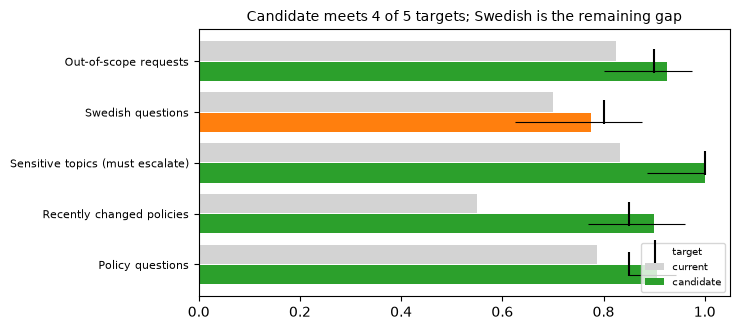

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(raw))
ax.barh(y + 0.2, raw["current"], height=0.38, color="lightgrey", label="current")
ax.barh(y - 0.2, raw["candidate"], height=0.38, color=np.where(raw["meets_target"], "tab:green", "tab:orange"), label="candidate")
ax.errorbar(raw["candidate"], y - 0.2, xerr=[raw["candidate"] - raw["ci_low"], raw["ci_high"] - raw["candidate"]], fmt="none", ecolor="k", lw=0.8)
ax.scatter(raw["target"], y, marker="|", s=300, color="k", label="target")
ax.set_yticks(y); ax.set_yticklabels(raw["slice"], fontsize=8); ax.set_xlim(0, 1.05)
n_met = int(raw["meets_target"].sum())
ax.set_title(f"Candidate meets {n_met} of {len(raw)} targets; Swedish is the remaining gap" if n_met < len(raw) else "Candidate meets every target", fontsize=10)
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

In [18]:
def one_pager(df: pd.DataFrame) -> str:
    met, total = int(df["meets_target"].sum()), len(df)
    gaps = df[~df["meets_target"]]
    biggest = df.assign(gain=df["candidate"] - df["current"]).sort_values("gain", ascending=False).iloc[0]
    decision = "Ship the candidate to all users" if met == total else (
        "Ship the candidate for English users now; keep the current version for " + ", ".join(gaps["slice"]) + " until the gap is closed")
    lines = [
        "### HR assistant: release decision (one page)",
        f"**Recommendation:** {decision}.",
        "",
        "**Why**",
        f"- The candidate meets **{met} of {total}** agreed quality targets on {int(df['n'].sum())} test questions.",
        f"- Largest improvement: *{biggest['slice']}*, from {biggest['current']:.0%} to {biggest['candidate']:.0%}.",
        f"- Sensitive topics: {df.loc[df['slice'].str.startswith('Sensitive'), 'candidate'].iloc[0]:.0%} escalated correctly (target 100%).",
    ]
    for _, g in gaps.iterrows():
        lines.append(f"- Gap: *{g['slice']}* at {g['candidate']:.0%} (95% CI {g['ci_low']:.0%}-{g['ci_high']:.0%}) vs target {g['target']:.0%}; based on {g['n']} questions.")
    lines += ["", "**Risks:** small test sets for some slices (wide intervals); policies change monthly, so the 'recently changed' slice must be refreshed.",
              "", "**Decision needed by Friday:** approve the partial rollout above; owner for the Swedish fix: applied AI team, target 4 weeks."]
    return "\n".join(lines)

display(Markdown(one_pager(raw)))

### HR assistant: release decision (one page)
**Recommendation:** Ship the candidate for English users now; keep the current version for Swedish questions until the gap is closed.

**Why**
- The candidate meets **4 of 5** agreed quality targets on 300 test questions.
- Largest improvement: *Recently changed policies*, from 55% to 90%.
- Sensitive topics: 100% escalated correctly (target 100%).
- Gap: *Swedish questions* at 78% (95% CI 62%-88%) vs target 80%; based on 40 questions.

**Risks:** small test sets for some slices (wide intervals); policies change monthly, so the 'recently changed' slice must be refreshed.

**Decision needed by Friday:** approve the partial rollout above; owner for the Swedish fix: applied AI team, target 4 weeks.

**What just happened?** The engineering table had five slices, ten numbers and confidence intervals. The one-pager leads with a **recommendation**, gives three reasons, names the one gap honestly with its uncertainty, lists the risks, and states the **decision needed, by when, and the owner**. The chart title says the message. Because the text is generated from the data, it updates when the eval is re-run.

**Executive summary checklist:** decision or recommendation in the first line; at most 3-5 supporting points; numbers compared with targets or baselines; uncertainty where it matters; risks; the ask, the owner and the date.

---
## 9. Writing technical documents

**What they are.**

| Document | Purpose | Typical length | Typical sections |
|---|---|---|---|
| **Design doc** | Agree how something will be built *before* building it; record the trade-offs | 3-10 pages | Context, goals and non-goals, proposed design, alternatives considered, risks, rollout, open questions |
| **RFC** (request for comments) | Propose a change and collect feedback from a wider group (used in many engineering organisations and in internet standards) | 2-8 pages | Summary, motivation, proposal, drawbacks, alternatives, unresolved questions |
| **ADR** (architecture decision record) | Record one decision and why it was made | Half a page | Title, status, context, decision, consequences |
| **Reference architecture** | A reusable, approved design for a common need (for example "RAG over SharePoint with per-user permissions") | Diagram + 2-5 pages | Diagram, components, data flows, security controls, variants, known limits |
| **Runbook / playbook** | How to operate or repeat something | Varies | See [notebook 02, section 13](02_forward_deployed_engineering_in_practice.ipynb) |
| **Narrative memo** (for example a "six-pager") | A decision document read in silence at the start of a meeting, instead of slides | 1-6 pages | Problem, data, options, recommendation, FAQ |

**Simple analogy.** A design doc is the architect's plan before building; an ADR is the note in the margin that says "we used steel here, not wood, because of fire rules".

**How to write well.** Write for a busy reader: summary first; short sentences; one idea per paragraph; diagrams for structure; numbers with units; explicit **non-goals**; alternatives you rejected **and why**; open questions. Ask a reviewer to read it before the meeting. Keep docs next to the code (for example Markdown in the repository) so they stay current.

**When to write one.** A design doc or RFC when a change is expensive to reverse or affects other teams; an ADR for every significant architecture decision; a reference architecture when the same design is needed for the third time.

In [19]:
DESIGN_DOC_TEMPLATE = '''# Design doc: <title>
**Author:** <name> | **Reviewers:** <names> | **Status:** draft | **Date:** <date>

## Summary
## Context and problem
## Goals
## Non-goals
## Proposed design
## Alternatives considered
## Evaluation plan and success metrics
## Security, privacy and cost
## Rollout and rollback
## Risks and open questions
'''

ADR_TEMPLATE = '''# ADR-007: Use a model router for the HR assistant
**Status:** accepted (2026-11-04)
## Context
Most questions are simple; a few need a large model. The large model costs about 3.5x more per task.
## Decision
Route by a small classifier: simple -> small model, complex or low-confidence -> large model.
## Consequences
Lower average cost; one more component to monitor; router accuracy is now part of the eval suite.
'''

REQUIRED_SECTIONS = {"design doc": ["Summary", "Goals", "Non-goals", "Proposed design", "Alternatives considered",
                                    "Evaluation plan", "Security", "Rollout", "Risks"],
                     "adr": ["Status", "Context", "Decision", "Consequences"]}

def lint_doc(text: str, kind: str) -> dict:
    # A tiny document checker: required sections present? numbers have units? very long sentences?
    missing = [s for s in REQUIRED_SECTIONS[kind] if s.lower() not in text.lower()]
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", re.sub(r"#.*", "", text)) if s.strip()]
    long_sentences = [s[:60] + "..." for s in sentences if len(s.split()) > 35]
    vague = [w for w in ["fast", "scalable", "robust", "soon", "easy"] if re.search(rf"\b{w}\b", text.lower())]
    return {"missing_sections": missing, "long_sentences": long_sentences, "vague_words_to_quantify": vague}

draft = '''# Design doc: HR assistant v2
## Summary
We will make the assistant fast and scalable and ship it soon.
## Goals
Better answers.
## Proposed design
Add retrieval filters and a router.
'''
print("template check:", lint_doc(DESIGN_DOC_TEMPLATE, "design doc"))
print("draft check:   ", lint_doc(draft, "design doc"))
print("ADR check:     ", lint_doc(ADR_TEMPLATE, "adr"))

template check: {'missing_sections': [], 'long_sentences': [], 'vague_words_to_quantify': []}
draft check:    {'missing_sections': ['Non-goals', 'Alternatives considered', 'Evaluation plan', 'Security', 'Rollout', 'Risks'], 'long_sentences': [], 'vague_words_to_quantify': ['fast', 'scalable', 'soon']}
ADR check:      {'missing_sections': [], 'long_sentences': [], 'vague_words_to_quantify': []}


**What just happened?** The checker finds what reviewers usually point out in a first draft: missing non-goals, no alternatives, no evaluation plan, no rollout, and vague words ("fast", "scalable", "soon") that should be numbers ("p95 under 3 s at 50 requests per second", "ship by 15 January"). The ADR passes: it is short, dated and says what the decision costs.

For larger examples of design docs and system-design write-ups, see [AI system design](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb), [RAG at scale](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) and the design doc in [building and shipping an AI feature](../23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb). For research write-ups, [paper writing](../24_Research_Methods/05_paper_writing_and_publishing.ipynb).

---
## 10. Recap

| Topic | Key idea | Runnable artefact here |
|---|---|---|
| Problem framing | Use the simplest tool that works; AI only where variety and language need it | Approach recommender |
| Defining quality | Error analysis -> failure taxonomy -> eval checks | Failure taxonomy table |
| Eval-driven roadmap | Each item fixes a failure mode and has an eval target | Ranked roadmap |
| Human in the loop | Suggest / approve / auto with gate / escalate; threshold from an error budget | Automation vs error curve |
| Pricing | Per seat, usage, outcome, hybrid; protect gross margin across usage levels | Margin simulation |
| Build vs buy vs partner | Build differentiators, buy commodities; compare 3-year TCO; write a decision trigger | Decision matrix + TCO |
| Vendor / model evaluation | Hard gates, your own eval set, weights agreed first, Pareto view | Scorecard + Pareto chart |
| Strategy | CoE operating models; portfolio under budget and risk; shared platforms | Portfolio selector |
| Governance | Inventory + risk tiers with matching controls | Risk-tier function |
| Pre-sales | Technical win; RFI / RFP / RFQ; compliance matrix; POC success plan | Compliance matrix |
| GTM | Roles, sales stages, BANT / MEDDICC as checklists for understanding a purchase | MEDDPICC gap list |
| Competition | Honest, dated, evidence-based; positioning "for whom" | Lead / trail analysis |
| Presenting | Answer first, evidence next; chart titles state the message | Executive one-pager |
| Writing | Design docs, RFCs, ADRs, reference architectures; non-goals and alternatives | Doc checker |

## Interview questions

1. **A stakeholder wants "an AI chatbot for HR". What do you ask first?**
   Who asks what, how often, what it costs today, which questions repeat, what a wrong answer would cause, and what success looks like. Then decide whether an FAQ, search, an LLM assistant or a mix fits best.
2. **How do you define quality for an LLM feature?**
   Read real outputs, write down failures, group them into a failure taxonomy, and turn the top modes into specific eval checks with targets; validate any LLM judge against human labels.
3. **What is an eval-driven roadmap?**
   A roadmap where each item targets a measured failure mode and has an eval slice and target that decide whether it is done.
4. **Per-seat vs usage vs outcome pricing for an AI product: trade-offs?**
   Per seat is simple but heavy users can make margins negative; usage tracks cost but bills are less predictable; outcome matches customer value but needs a precise, measurable outcome. Hybrids are common.
5. **How do you decide build vs buy?**
   Differentiator vs commodity, weighted criteria (fit, time, cost, control, maintainability, lock-in), 3-year TCO including hidden costs, risks, and a written trigger for revisiting.
6. **How would you choose between three LLMs for a product?**
   Apply hard gates (residency, data terms, compliance), run your own eval set for quality, latency and cost per task, weight the criteria agreed in advance, look at the Pareto frontier, consider routing, and re-run the evaluation as models change.
7. **What is MEDDICC and why would an engineer care?**
   A deal-qualification checklist (metrics, economic buyer, decision criteria, decision process, identify pain, champion, competition). Several parts are technical: metrics become success criteria, decision criteria are often technical requirements, and the paper process includes the security review.
8. **RFI vs RFP vs RFQ?**
   RFI gathers information for a shortlist; RFP compares detailed proposals against requirements; RFQ compares prices for a defined need.
9. **How do you present eval results to an executive?**
   Recommendation first, 3-5 supporting points compared with targets, honest gaps with uncertainty, risks, and the decision needed with owner and date; one chart whose title states the message.
10. **What makes a good design doc?**
    A clear problem, goals and non-goals, the proposed design, alternatives considered and why they were rejected, an evaluation plan, security and cost, rollout and rollback, and open questions.

## Further reading

- Marty Cagan, *Inspired: How to Create Tech Products Customers Love* (2nd ed., Wiley, 2017), and the Silicon Valley Product Group (SVPG) articles on product discovery.
- Teresa Torres, *Continuous Discovery Habits* (2021).
- Hamel Husain, "Your AI Product Needs Evals" and "A Field Guide to Rapidly Improving AI Products" (hamel.dev); Eugene Yan, "Patterns for Building LLM-based Systems and Products" (eugeneyan.com).
- Chip Huyen, *AI Engineering* (O'Reilly, 2025), chapters on evaluation and on the economics of AI applications.
- Google People + AI Research (PAIR), *People + AI Guidebook* (human-in-the-loop and trust patterns).
- Barbara Minto, *The Pyramid Principle* (Pearson); Cole Nussbaumer Knaflic, *Storytelling with Data* (Wiley, 2015).
- Malte Ubl, "Design Docs at Google" (industrialempathy.com, 2020); Michael Nygard, "Documenting Architecture Decisions" (2011, the original ADR post).
- MEDDICC: meddicc.com (definitions of each letter) and Andy Whyte, *MEDDICC: The Ultimate Guide to Staying One Step Ahead in the Complex Sale* (2020).
- Microsoft Cloud Adoption Framework, AI strategy and AI adoption guidance (learn.microsoft.com), on choosing the option "with the least operational responsibility" and on AI centres of excellence.
- Sierra, "Outcome-based pricing for AI agents" (sierra.ai blog, 2024); Intercom Fin pricing page (a per-outcome price) as a public example.
- Oxide Computer, "RFD 1: Requests for Discussion"; Jeff Bezos, 2017 Amazon shareholder letter (on six-page narrative memos).
- Prosci ADKAR and John Kotter's *Leading Change* for transformation; ISO/IEC 42001 (AI management systems); NIST AI Risk Management Framework (AI RMF 1.0, 2023).
- In this repo: [02 forward deployed engineering in practice](02_forward_deployed_engineering_in_practice.ipynb), [model comparison and selection](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb), [cloud cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb), [responsible-AI product review](../00_AI_Fundamentals/07_industry_responsible_ai_product_review.ipynb), [research methods](../24_Research_Methods/README.md).